## Florida wetland fate, 2022 to 2024

Every 2022 wetland pixel from `data/wetland_sample_labels_2022_2024.parquet`, colored by what it became in 2024.
Land cover comes from Annual NLCD Collection 1 v2 (`Annual_NLCD_LndCov_{2022,2024}_CU_C1V2`), at 30 m on the NLCD Albers grid (EPSG:5070).

Remained wetland is drawn as a 300 m raster, where a cell is filled if it holds any wetland pixel.
The two converted classes are drawn as point markers on top of it. They're only about 0.33% of pixels and would disappear at 30 m on a slide, so the markers make their area look bigger than it is.
Read this map as showing where conversion happens, not how much area converted.

The three classes use pale sage, vermillion and navy, chosen to differ in lightness as well as hue.
I checked them with simulated deutan, protan and tritan color blindness (colorspacious, OKLab ΔE ×100, target 8).
The closest pair is 14.9 (remained wetland against the gray land fill, protan). The old aqua, orange and blue palette bottomed out at 9.2, because aqua and orange have the same lightness and a deutan viewer can only separate them by hue.

In [8]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pyarrow.parquet as pq
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from matplotlib.lines import Line2D

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA = ROOT / "data"

# the parquet carries no CRS. x/y are on the NLCD Albers grid (lat_0 23, lon_0 96 W,
# parallels 29.5 and 45.5), which is EPSG:5070 up to a sub meter datum difference.
# Same call export_val_predictions.py makes, and the NLCD rasters are no longer on disk.
nlcd_crs = "EPSG:5070"

t = pq.read_table(DATA / "wetland_sample_labels_2022_2024.parquet", columns=["x", "y", "label"])
x = t["x"].to_numpy()
y = t["y"].to_numpy()
label = t["label"].to_numpy()
del t

counts = np.bincount(label, minlength=3)
print("pixels per label:", dict(zip(["remained", "developed", "other"], counts)))
print(f"positive rate (developed): {counts[1] / counts.sum():.4%}")

states = gpd.read_file(DATA / "boundaries/cb_2023_us_state_500k/cb_2023_us_state_500k.shp")
florida = states[states.STUSPS == "FL"].to_crs(nlcd_crs)

pixels per label: {'remained': np.int64(58961672), 'developed': np.int64(66456), 'other': np.int64(130726)}
positive rate (developed): 0.1123%


In [9]:
# 59M points won't scatter, so bin remained wetland onto a 300 m grid (10 by 10 NLCD pixels)
CELL_M = 300
xmin, xmax = x.min(), x.max()
ymin, ymax = y.min(), y.max()
ncol = int((xmax - xmin) // CELL_M) + 1
nrow = int((ymax - ymin) // CELL_M) + 1

keep = label == 0
ci = ((x[keep] - xmin) // CELL_M).astype(np.int64)
ri = ((ymax - y[keep]) // CELL_M).astype(np.int64)
wet = np.zeros((nrow, ncol), dtype=bool)
wet[ri, ci] = True
wet_extent = (xmin, xmin + ncol * CELL_M, ymax - nrow * CELL_M, ymax)

dev = label == 1
oth = label == 2

In [10]:
import json

import pandas as pd
from sklearn.metrics import average_precision_score, precision_recall_curve

# Same run as the zoom figure further down. The max F1 threshold is picked on the very
# predictions it's scored on, so these numbers are an upper bound, not what a threshold
# fixed ahead of time would get. Scores aren't calibrated either, so the threshold itself
# only means something within this run.
F1_RUN = ROOT / "results/tcn_2022_2024_batch_size_2048"


def max_f1(y, p):
    pr, rc, th = precision_recall_curve(y, p)
    # last pr/rc point has no threshold, it's the recall 0 anchor
    f1 = 2 * pr[:-1] * rc[:-1] / np.maximum(pr[:-1] + rc[:-1], 1e-12)
    i = int(np.argmax(f1))
    pred = p >= th[i]
    tp = int((pred & (y == 1)).sum())
    fp = int((pred & (y == 0)).sum())
    fn = int((~pred & (y == 1)).sum())
    return dict(threshold=th[i], precision=pr[i], recall=rc[i], f1=f1[i],
                auprc=average_precision_score(y, p), tp=tp, fp=fp, fn=fn,
                tn=len(y) - tp - fp - fn, positives=int(y.sum()), pixels=len(y),
                positive_rate=y.mean())


rows, all_y, all_p = [], [], []
for f in sorted(F1_RUN.glob("fold_*/val_preds.npz")):
    with np.load(f) as z:
        y, p = z["labels"].astype(np.int8), z["probs"].astype(np.float64)
    rows.append(dict(fold=f.parent.name, **max_f1(y, p)))
    all_y.append(y)
    all_p.append(p)
# every pixel is held out in exactly one fold, so pooling covers the whole state once.
# One threshold across three different fold models is a bit unfair to them, hence the per fold rows too.
rows.append(dict(fold="pooled", **max_f1(np.concatenate(all_y), np.concatenate(all_p))))

best_f1 = pd.DataFrame(rows).set_index("fold")
print(f"run: {F1_RUN.relative_to(ROOT)}, arrays: {json.loads((F1_RUN / 'manifest.json').read_text())['arrays']['git_commit'][:7]}")
pooled = best_f1.loc["pooled"]
print(f"pooled confusion matrix at threshold {pooled.threshold:.4f} (rows true, cols predicted)")
print(pd.DataFrame([[pooled.tn, pooled.fp], [pooled.fn, pooled.tp]],
                   index=["not developed", "developed"], columns=["not developed", "developed"]).astype(int))
best_f1.style.format({"threshold": "{:.4f}", "precision": "{:.3f}", "recall": "{:.3f}", "f1": "{:.3f}",
                      "auprc": "{:.3f}", "positive_rate": "{:.4%}",
                      **{c: "{:,}" for c in ["tp", "fp", "fn", "tn", "positives", "pixels"]}})

run: results/tcn_2022_2024_batch_size_2048, arrays: 868089f
pooled confusion matrix at threshold 0.6376 (rows true, cols predicted)
               not developed  developed
not developed       58886946      44948
developed              50904      14341


,threshold,precision,recall,f1,auprc,tp,fp,fn,tn,positives,pixels,positive_rate
fold,,,,,,,,,,,,
fold_0,0.6204,0.243,0.214,0.228,0.157,"5,308","16,562","19,466","19,607,653","24,774","19,648,989",0.1261%
fold_1,0.6437,0.246,0.226,0.235,0.158,"4,457","13,657","15,299","19,619,759","19,756","19,653,172",0.1005%
fold_2,0.6494,0.237,0.229,0.233,0.155,"4,745","15,305","15,970","19,658,958","20,715","19,694,978",0.1052%
pooled,0.6376,0.242,0.220,0.230,0.154,"14,341","44,948","50,904","58,886,946","65,245","58,997,139",0.1106%


IndexError: boolean index did not match indexed array along axis 0; size of axis is 19694978 but size of corresponding boolean axis is 59158854

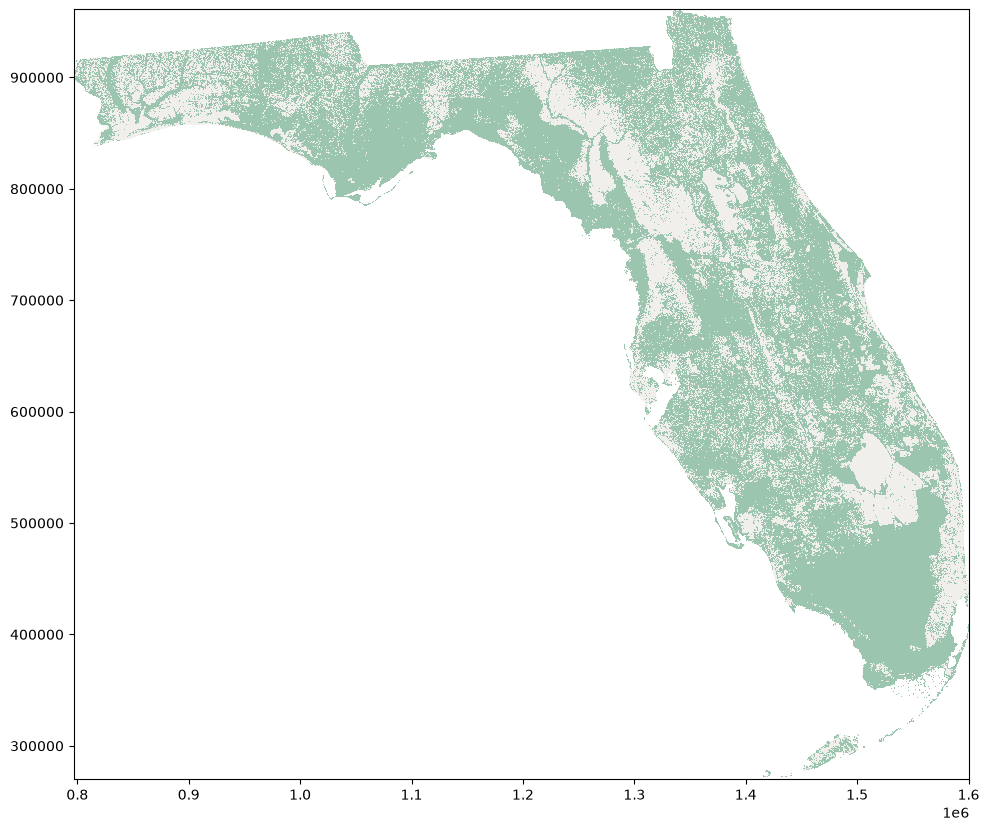

In [11]:
# spread across lightness (OKLab L 0.79, 0.63, 0.37), not just hue, so the classes still
# separate under color blindness and in grayscale. The pale wetland also lets the rare classes pop.
C_WET, C_DEV, C_OTH = "#9cc5b0", "#e05a12", "#173a85"
INK, MUTED, LAND = "#0b0b0b", "#52514e", "#f0efec"
KM = 1000.0

fig, ax = plt.subplots(figsize=(12, 10))
florida.plot(ax=ax, color=LAND, edgecolor="none", zorder=0)
ax.imshow(np.ma.masked_where(~wet, wet), cmap=ListedColormap([C_WET]), extent=wet_extent,
          interpolation="nearest", zorder=1)
# other first so developed, the class we care about, sits on top where they overlap
ax.scatter(x[oth], y[oth], s=1.5, c=C_OTH, linewidths=0, rasterized=True, zorder=2)
ax.scatter(x[dev], y[dev], s=1.5, c=C_DEV, linewidths=0, rasterized=True, zorder=3)
florida.boundary.plot(ax=ax, color=MUTED, linewidth=0.8, zorder=4)

ax.set_title("Florida Wetland Fate (2022 - 2024)", fontsize=26, color=INK, pad=14)
ax.set_xlabel("Easting (km)", fontsize=16, color=MUTED)
ax.set_ylabel("Northing (km)", fontsize=16, color=MUTED)
ax.xaxis.set_major_formatter(lambda v, _: f"{v / KM:,.0f}")
ax.yaxis.set_major_formatter(lambda v, _: f"{v / KM:,.0f}")
ax.tick_params(labelsize=13, colors=MUTED)
for s in ax.spines.values():
    s.set_color("#c3c2b7")
ax.set_aspect("equal")

handles = [Line2D([], [], marker="s", ls="", ms=14, color=c, label=n) for c, n in [
    (C_WET, "Remained wetland"),
    (C_DEV, "Converted to developed"),
    (C_OTH, "Converted to other (not developed)"),
]]
ax.legend(handles=handles, loc="lower left", fontsize=16, frameon=False, labelcolor=INK)

fig.tight_layout()
out = ROOT / "results/figures/florida_wetland_fate_2024.png"
out.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(out, dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

## What the embeddings look like over the same wetlands

Same wetland population as above, now colored by single AlphaEarth bands instead of by fate.
Embeddings are the 2022 annual AlphaEarth layer (bands `A00_2022` to `A63_2022`) from `data/alphaearth_wetland_joined_2022_2024/`.
That year is the base year, so nothing here peeks at the 2024 outcome.
The joined table has 58,997,139 of the 59,158,854 wetland pixels. The 161,715 that only became wetland after 2019 aren't in it (see `build_joined_2022_2024.py`).

Each band is averaged over the wetland pixels in each 1 km cell.
I picked the bands by map shape, not by hand: start with the band whose 1 km map varies the most, then keep adding the band whose map has the lowest maximum absolute correlation with the bands already picked.
The correlation table is printed below the band picking cell.

Each panel uses viridis stretched from the 2nd to the 98th percentile of that band's 1 km means. The bands span different ranges, so each one gets its own scale.
That shows each band's spatial pattern, but it drops the sign: 0 falls at a different color in each panel, and band 63 is positive almost everywhere.

In [ ]:
EMB_DIR = DATA / "alphaearth_wetland_joined_2022_2024"
BANDS = [f"A{b:02d}_2022" for b in range(64)]

# 1 km cells on the same origin as the 300 m grid above
EMB_CELL_M = 1000
encol = int((xmax - xmin) // EMB_CELL_M) + 1
enrow = int((ymax - ymin) // EMB_CELL_M) + 1

band_sum = np.zeros((len(BANDS), enrow * encol))
n_px = np.zeros(enrow * encol)
for f in sorted(EMB_DIR.glob("*.parquet")):
    t = pq.read_table(f, columns=["x", "y", *BANDS])
    cx = ((t["x"].to_numpy() - xmin) // EMB_CELL_M).astype(np.int64)
    cy = ((ymax - t["y"].to_numpy()) // EMB_CELL_M).astype(np.int64)
    cell = cy * encol + cx
    n_px += np.bincount(cell, minlength=n_px.size)
    for i, b in enumerate(BANDS):
        band_sum[i] += np.bincount(cell, weights=t[b].to_numpy(), minlength=n_px.size)

has = n_px > 0
band_mean = np.full_like(band_sum, np.nan)
band_mean[:, has] = band_sum[:, has] / n_px[has]
print(f"{int(n_px.sum()):,} pixels in {has.sum():,} occupied 1 km cells")

58,997,139 pixels in 134,410 occupied 1 km cells


In [ ]:
import pandas as pd

M = band_mean[:, has]
corr = np.corrcoef(M)
picked = [int(np.argmax(M.std(axis=1)))]
while len(picked) < 3:
    worst = np.abs(corr[:, picked]).max(axis=1)
    worst[picked] = np.inf
    picked.append(int(np.argmin(worst)))

names = [BANDS[i] for i in picked]
print("picked:", names)
print("1 km cell standard deviation:", np.round(M[picked].std(axis=1), 4))
pd.DataFrame(corr[np.ix_(picked, picked)], index=names, columns=names).round(3)

picked: ['A36_2022', 'A31_2022', 'A63_2022']
1 km cell standard deviation: [0.1266 0.0647 0.047 ]


,A36_2022,A31_2022,A63_2022
A36_2022,1.000,-0.008,-0.047
A31_2022,-0.008,1.000,0.117
A63_2022,-0.047,0.117,1.000


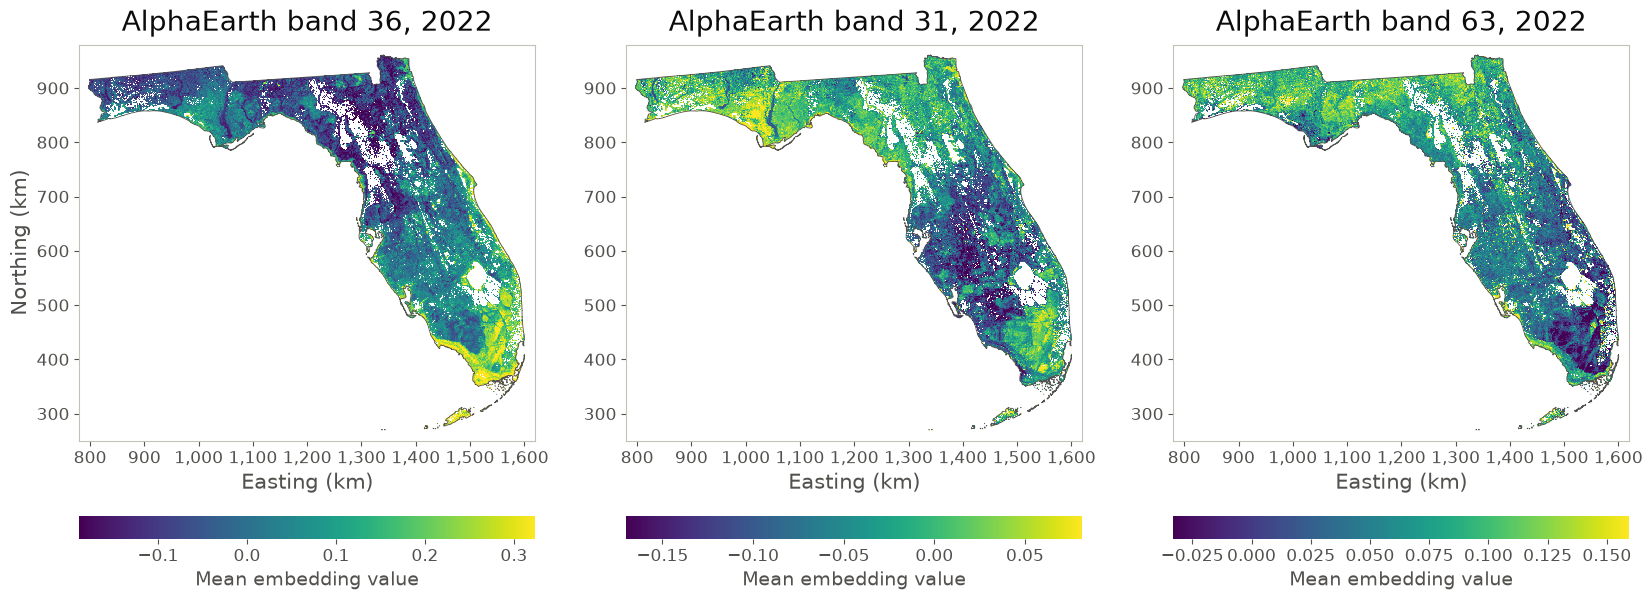

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(20, 7.5))
for ax, bi in zip(axes, picked):
    img = band_mean[bi].reshape(enrow, encol)
    lo, hi = np.nanpercentile(img, [2, 98])
    im = ax.imshow(np.ma.masked_invalid(img), cmap="viridis", vmin=lo, vmax=hi,
                   extent=(xmin, xmin + encol * EMB_CELL_M, ymax - enrow * EMB_CELL_M, ymax),
                   interpolation="nearest", zorder=1)
    florida.boundary.plot(ax=ax, color=MUTED, linewidth=0.6, zorder=2)

    ax.set_title(f"AlphaEarth band {bi}, 2022", fontsize=20, color=INK, pad=10)
    ax.set_xlabel("Easting (km)", fontsize=15, color=MUTED)
    ax.xaxis.set_major_formatter(lambda v, _: f"{v / KM:,.0f}")
    ax.yaxis.set_major_formatter(lambda v, _: f"{v / KM:,.0f}")
    ax.tick_params(labelsize=12, colors=MUTED)
    for s in ax.spines.values():
        s.set_color("#c3c2b7")
    ax.set_aspect("equal")
    ax.set_xlim(780_000, 1_620_000)
    ax.set_ylim(250_000, 980_000)

    cb = fig.colorbar(im, ax=ax, orientation="horizontal", fraction=0.05, pad=0.13)
    cb.set_label("Mean embedding value", fontsize=14, color=MUTED)
    cb.ax.tick_params(labelsize=12, colors=MUTED)
    cb.outline.set_visible(False)
axes[0].set_ylabel("Northing (km)", fontsize=15, color=MUTED)

out = ROOT / "results/figures/florida_wetland_embedding_bands_2022.png"
fig.savefig(out, dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

## Where the model works: one zoomed in area, and the statewide PR curve

Model: the temporal CNN in `results/tcn_2022_2024_batch_size_2048` (focal loss with gamma 2, no pos_weight, 3 spatially blocked folds, seed 0).
Inputs are AlphaEarth embeddings for 2017 to 2022 and `dist_to_developed_2022_m`, read from `data/arrays_2022_2024` (git `868089f`).
The target is converted to developed by 2024 versus everything else, so "converted to other" counts as a negative. In the fate panel those pixels are drawn green with remained wetland, to match how the model treats them. There are 207 of them in this window.

In both maps, anything that wasn't wetland in 2022 is filled with dark gray (`#6e6e6e`). I checked that gray against the orange score ramp and the fate colors under simulated deutan, protan and tritan color blindness. The closest pair is 9.3 OKLab ΔE ×100 (protan, against the ramp), above the 8 target. Lighter grays fell under 6 against the pale end of the ramp.

Every pixel is scored by the fold model that didn't train on its block. `export_val_predictions.stitch` puts the three `val_preds.npz` files back into pixel order and checks the saved labels row by row.

This area was picked on purpose to show the model at its best, so it isn't a typical area. To pick it, I cut the state into 15 km by 15 km windows (500 by 500 pixels) and kept the ones with at least 150 developed conversions and at least 50,000 wetland pixels. Then I took the window with the highest AUPRC.
That rule throws out tiny windows that are mostly conversion, where a high AUPRC is easy. The top candidates and the median window are printed below the window search cell.
The PR panel shows this window's curve next to the statewide one so you can see how much better it is than average.

Probabilities aren't calibrated (focal loss, no calibration step), so read the middle panel as a ranking, not as real chances of conversion.

In [ ]:
import json
import sys

from sklearn.metrics import average_precision_score, precision_recall_curve

sys.path.insert(0, str(ROOT))
import export_val_predictions as evp

RUN = ROOT / "results/tcn_2022_2024_batch_size_2048"
run_manifest = json.loads((RUN / "manifest.json").read_text())
run_manifest["population_stats_path"] = str(DATA / "population_stats_2022_2024.json")
ARR = ROOT / run_manifest["arrays"]["path"]
arr_manifest = json.loads((ARR / "manifest.json").read_text())

arrays = {"label": np.load(ARR / "label.npy"), "block_code": np.load(ARR / "block_code.npy")}
prob, target, n_scored = evp.stitch(RUN, arrays, arr_manifest, run_manifest)
assert n_scored == arr_manifest["total_rows"]
label_raw = np.load(ARR / "label_raw.npy")
rowcol = np.load(ARR / "rowcol.npy")
grid_x0, grid_y0 = evp.grid_origin(rowcol, np.load(ARR / "xy.npy", mmap_mode="r"))

WIN = 500
win_key = (rowcol[:, 0] // WIN).astype(np.int64) * 100_000 + rowcol[:, 1] // WIN
keys, inv = np.unique(win_key, return_inverse=True)
win_px = np.bincount(inv)
win_pos = np.bincount(inv, weights=target)
order = np.argsort(inv, kind="stable")
edges = np.r_[0, np.cumsum(win_px)]

rows = []
for k in np.where((win_pos >= 150) & (win_px >= 50_000))[0]:
    idx = order[edges[k]:edges[k + 1]]
    rows.append(dict(win_row=keys[k] // 100_000, win_col=keys[k] % 100_000, pixels=win_px[k],
                     converted=int(win_pos[k]), positive_rate=win_pos[k] / win_px[k],
                     auprc=average_precision_score(target[idx], prob[idx])))
windows = pd.DataFrame(rows).sort_values("auprc", ascending=False, ignore_index=True)
print(f"{len(windows)} windows pass, median AUPRC {windows.auprc.median():.3f}")
best = windows.iloc[0]
windows.head(5).round(4)

  fold 0:   19,648,989 rows,  24,774 positives


  fold 1:   19,653,172 rows,  19,756 positives


  fold 2:   19,694,978 rows,  20,715 positives


74 windows pass, median AUPRC 0.165


,win_row,win_col,pixels,converted,positive_rate,auprc
0,20,47,154520,664,0.0043,0.6844
1,32,40,61017,392,0.0064,0.5869
2,18,47,73210,535,0.0073,0.4178
3,15,43,65337,342,0.0052,0.3686
4,28,39,84117,1165,0.0138,0.3361


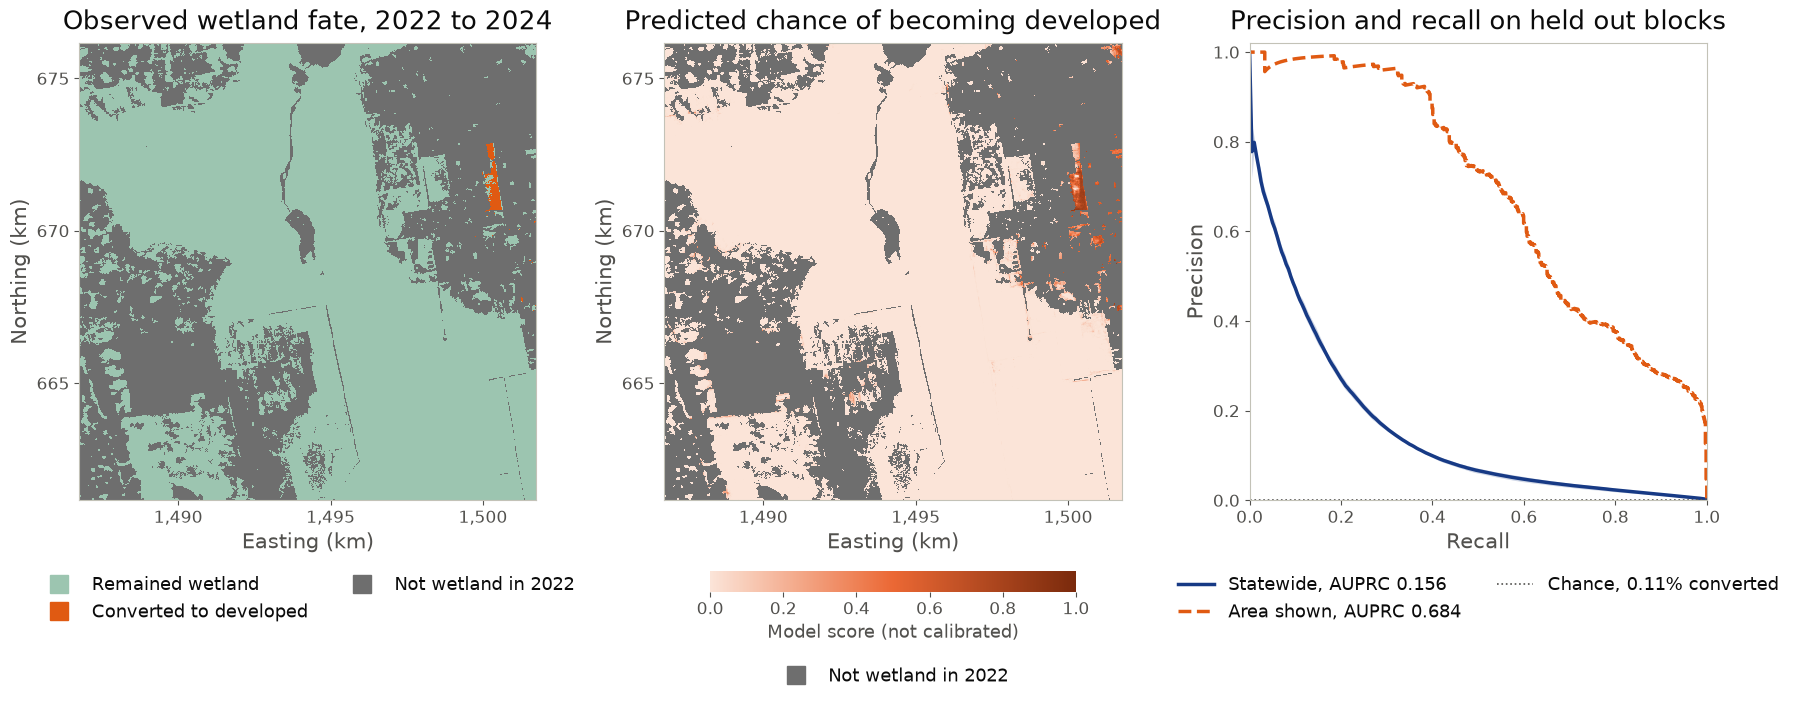

207 converted to other pixels drawn as remained wetland in the fate panel
window rows 10000 to 10500, cols 23500 to 24000, 154,520 wetland px, 664 converted (0.430%)
statewide: 65,245 converted of 58,997,139 (0.1106%), fold AUPRC 0.156 plus or minus 0.001


In [ ]:
r0, c0 = int(best.win_row) * WIN, int(best.win_col) * WIN
in_win = order[edges[np.searchsorted(keys, best.win_row * 100_000 + best.win_col)]:
               edges[np.searchsorted(keys, best.win_row * 100_000 + best.win_col) + 1]]
rr, cc = rowcol[in_win, 0] - r0, rowcol[in_win, 1] - c0

fate_img = np.full((WIN, WIN), np.nan)
# converted to other folds into remained wetland here, the same negative class the model trains on
fate_img[rr, cc] = np.where(label_raw[in_win] == 2, 0, label_raw[in_win])
prob_img = np.full((WIN, WIN), np.nan)
prob_img[rr, cc] = prob[in_win]
win_extent = (grid_x0 + c0 * 30, grid_x0 + (c0 + WIN) * 30, grid_y0 - (r0 + WIN) * 30, grid_y0 - r0 * 30)

# one fold per val_preds file, so the statewide curve can carry a fold to fold band
fold_curves, fold_ap = [], []
recall_grid = np.linspace(0, 1, 201)
for f in sorted(RUN.glob("fold_*/val_preds.npz")):
    with np.load(f) as z:
        pr, rc, _ = precision_recall_curve(z["labels"], z["probs"])
        fold_curves.append(np.interp(recall_grid, rc[::-1], pr[::-1]))
        fold_ap.append(average_precision_score(z["labels"], z["probs"]))
fold_curves = np.vstack(fold_curves)
state_mean, state_sd = fold_curves.mean(0), fold_curves.std(0, ddof=1)
win_pr, win_rc, _ = precision_recall_curve(target[in_win], prob[in_win])
state_rate = target.mean()

prob_cmap = LinearSegmentedColormap.from_list("prob", ["#fbe4d8", "#eb6834", "#7a2a0c"])
# masked cells stay transparent so the axes face shows through as the not wetland fill.
# This gray clears the CVD check against both the ramp and the fate colors, see markdown.
NOT_WET = "#6e6e6e"

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(21, 7.6), gridspec_kw={"wspace": 0.28})
ax1.imshow(np.ma.masked_invalid(fate_img), cmap=ListedColormap([C_WET, C_DEV]), vmin=-0.5, vmax=1.5,
           extent=win_extent, interpolation="nearest")
im = ax2.imshow(np.ma.masked_invalid(prob_img), cmap=prob_cmap, vmin=0, vmax=1,
                extent=win_extent, interpolation="nearest")

for ax, title in ((ax1, "Observed wetland fate, 2022 to 2024"),
                  (ax2, "Predicted chance of becoming developed")):
    ax.set_facecolor(NOT_WET)
    ax.set_title(title, fontsize=19, color=INK, pad=10)
    ax.set_xlabel("Easting (km)", fontsize=15, color=MUTED)
    ax.set_ylabel("Northing (km)", fontsize=15, color=MUTED)
    ax.xaxis.set_major_formatter(lambda v, _: f"{v / KM:,.0f}")
    ax.yaxis.set_major_formatter(lambda v, _: f"{v / KM:,.0f}")
    ax.locator_params(nbins=4)

ax1.legend(handles=[Line2D([], [], marker="s", ls="", ms=13, color=c, label=n) for c, n in [
    (C_WET, "Remained wetland"), (C_DEV, "Converted to developed"), (NOT_WET, "Not wetland in 2022")]],
    loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2, fontsize=13, frameon=False, labelcolor=INK)
# inset rather than ax=, which would shrink this map out of line with its neighbors
cb = fig.colorbar(im, cax=ax2.inset_axes([0.1, -0.2, 0.8, 0.045]), orientation="horizontal")
cb.set_label("Model score (not calibrated)", fontsize=13, color=MUTED)
cb.ax.tick_params(labelsize=12, colors=MUTED)
cb.outline.set_visible(False)
ax2.legend(handles=[Line2D([], [], marker="s", ls="", ms=13, color=NOT_WET, label="Not wetland in 2022")],
           loc="upper center", bbox_to_anchor=(0.5, -0.33), fontsize=13, frameon=False, labelcolor=INK)

ax3.fill_between(recall_grid, np.clip(state_mean - state_sd, 0, 1), np.clip(state_mean + state_sd, 0, 1),
                 color=C_OTH, alpha=0.2, linewidth=0)
ax3.plot(recall_grid, state_mean, color=C_OTH, linewidth=2.5,
         label=f"Statewide, AUPRC {np.mean(fold_ap):.3f}")
ax3.plot(win_rc, win_pr, color=C_DEV, linewidth=2.5, linestyle="--",
         label=f"Area shown, AUPRC {best.auprc:.3f}")
ax3.axhline(state_rate, color=MUTED, linewidth=1.2, linestyle=":",
            label=f"Chance, {state_rate:.2%} converted")
ax3.set_title("Precision and recall on held out blocks", fontsize=19, color=INK, pad=10)
ax3.set_xlabel("Recall", fontsize=15, color=MUTED)
ax3.set_ylabel("Precision", fontsize=15, color=MUTED)
ax3.set_xlim(0, 1)
ax3.set_ylim(0, 1.02)
ax3.set_box_aspect(1)
ax3.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2, fontsize=13, frameon=False, labelcolor=INK)

for ax in (ax1, ax2, ax3):
    ax.tick_params(labelsize=12, colors=MUTED)
    for s in ax.spines.values():
        s.set_color("#c3c2b7")

out = ROOT / "results/figures/zoom_prediction_and_pr_curve_2022_2024.png"
fig.savefig(out, dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

print(f"{int((label_raw[in_win] == 2).sum()):,} converted to other pixels drawn as remained wetland in the fate panel")
print(f"window rows {r0} to {r0 + WIN}, cols {c0} to {c0 + WIN}, "
      f"{len(in_win):,} wetland px, {int(target[in_win].sum())} converted ({target[in_win].mean():.3%})")
print(f"statewide: {int(target.sum()):,} converted of {len(target):,} ({state_rate:.4%}), "
      f"fold AUPRC {np.mean(fold_ap):.3f} plus or minus {np.std(fold_ap, ddof=1):.3f}")

## How much converted wetland each resolution finds, for a given amount of wetland flagged

Three models, each predicting conversion to developed from 2019 to 2024 at a different resolution:

* 30 m pixels: `results/tcn_batch_size_2048`, the pixel temporal CNN (focal loss, gamma 2, no pos_weight), arrays from `data/arrays` (git `88e677b`).
* 120 m cells: `results/cell_tcn_120m`, the cell temporal CNN regressing the share of each cell's wetland that became developed (MSE, weighted by wetland pixels), cells from `data/cells_2019_2024_120m`.
* 300 m cells: `results/cell_tcn_300m`, same setup on `data/cells_2019_2024_300m`.

All three are built from the same 59,267,331 wetland pixels (source arrays git `88e677b`) and use the same 5 spatially blocked folds with seed 0. A cell inherits the fold of the 10 km block it sits in, so every fold holds out the same ground at every resolution. The cell below checks this: per fold, the held out wetland pixels and converted pixels match exactly across the three runs.

How the curve is built: sort the held out units (pixels or cells) by predicted conversion share, highest first. For a pixel that share is just the model score. Walk down the list. The x axis is the wetland area covered so far over all held out wetland area, counting only the wetland inside each cell, not the whole cell. The y axis is the converted wetland area covered so far over all converted wetland area, where a cell's converted area is its observed share times its wetland area. The dotted diagonal is what a random ranking would get.

The curves pool all 5 folds, so each ranking mixes scores from 5 fold models. The 30 m scores aren't calibrated (focal loss), so that mixing could hurt or help a little. The per fold capture at 10% in the table is there to show the pooled number isn't an artifact of that.

Tied scores are handled as a block: the curve draws a straight line across each run of ties, which is what a random order inside the tie would give on average. Half the 30 m pixels share a score with another pixel, so this matters.

Positive rate: 0.28% of held out wetland area (165,908 of 59,267,331 pixels) converted to developed.

In [13]:
CAPTURE_RUNS = {
    "30 m pixels": ROOT / "results/tcn_batch_size_2048",
    "120 m cells": ROOT / "results/cell_tcn_120m",
    "300 m cells": ROOT / "results/cell_tcn_300m",
}


def load_held_out(run):
    """Pooled val predictions over all folds as (score, wetland px, converted px, fold).
    Areas are in 30 m pixels. Every pixel is 900 m2, so the unit cancels in the shares."""
    score, wet, conv, fold = [], [], [], []
    for i, f in enumerate(sorted(run.glob("fold_*/val_preds.npz"))):
        with np.load(f) as z:
            if "probs" in z:
                s, w, c = z["probs"], np.ones(len(z["probs"]), np.int64), z["labels"].astype(np.int64)
            else:
                # target is n_developed / n_wetland, so this gets the pixel count back
                s, w = z["pred"], z["n_wetland"].astype(np.int64)
                c = np.rint(z["target"].astype(np.float64) * w).astype(np.int64)
        score.append(s); wet.append(w); conv.append(c); fold.append(np.full(len(s), i, np.int8))
    return [np.concatenate(a) for a in (score, wet, conv, fold)]


def capture_curve(score, wet, conv):
    o = np.argsort(-score, kind="stable")
    cw = np.cumsum(wet[o], dtype=np.float64)
    cc = np.cumsum(conv[o], dtype=np.float64)
    # Keep only the last point of each run of tied scores. The 300 m model puts a lot of
    # cells at the same tiny score, and any order inside a tie would be arbitrary. A
    # straight line across the tie is the expected curve under a random order.
    s = score[o]
    last = np.r_[s[1:] != s[:-1], True]
    return np.r_[0, cw[last] / cw[-1]], np.r_[0, cc[last] / cc[-1]]


AREA_GRID = np.linspace(0, 1, 2001)
capture, held_out, rows = {}, {}, []
for name, run in CAPTURE_RUNS.items():
    score, wet, conv, fold = load_held_out(run)
    held_out[name] = [(int(wet[fold == k].sum()), int(conv[fold == k].sum())) for k in range(5)]
    x, y = capture_curve(score, wet, conv)
    capture[name] = np.interp(AREA_GRID, x, y)
    row = dict(resolution=name, units=len(score), wetland_px=int(wet.sum()), converted_px=int(conv.sum()),
               tied_scores=1 - len(x[1:]) / len(score),
               area_under_curve=np.trapezoid(capture[name], AREA_GRID))
    for top in (0.01, 0.05, 0.10, 0.25):
        row[f"capture_top_{top:.0%}"] = np.interp(top, x, y)
    # each fold scored on its own, so mixing fold models' scores in one ranking isn't
    # what's driving the pooled number
    row["capture_top_10%_by_fold"] = " ".join(
        f"{np.interp(0.10, *capture_curve(score[fold == k], wet[fold == k], conv[fold == k])):.3f}"
        for k in range(5))
    rows.append(row)
    del score, wet, conv, fold

# the same blocks are held out in every fold at every resolution, so these have to match exactly
ref = held_out["30 m pixels"]
assert all(v == ref for v in held_out.values()), held_out
tot_wet, tot_conv = map(sum, zip(*ref))
print("runs:", {k: str(v.relative_to(ROOT)) for k, v in CAPTURE_RUNS.items()})
print(f"held out wetland: {tot_wet:,} px ({tot_wet * 900 / 4046.86:,.0f} acres), "
      f"converted {tot_conv:,} px, positive rate {tot_conv / tot_wet:.4%}")
capture_table = pd.DataFrame(rows).set_index("resolution")
capture_table.style.format({"units": "{:,}", "wetland_px": "{:,}", "converted_px": "{:,}",
                            "tied_scores": "{:.2%}", "area_under_curve": "{:.3f}",
                            **{c: "{:.3f}" for c in capture_table.columns if c.startswith("capture_top") and "fold" not in c}})

runs: {'30 m pixels': 'results/tcn_batch_size_2048', '120 m cells': 'results/cell_tcn_120m', '300 m cells': 'results/cell_tcn_300m'}
held out wetland: 59,267,331 px (13,180,737 acres), converted 165,908 px, positive rate 0.2799%


,units,wetland_px,converted_px,tied_scores,area_under_curve,capture_top_1%,capture_top_5%,capture_top_10%,capture_top_25%,capture_top_10%_by_fold
resolution,,,,,,,,,,
30 m pixels,"59,267,331","59,267,331","165,908",51.68%,0.960,0.386,0.769,0.897,0.979,0.865 0.895 0.892 0.925 0.902
120 m cells,"5,359,945","59,267,331","165,908",46.53%,0.940,0.342,0.701,0.826,0.941,0.759 0.882 0.811 0.844 0.829
300 m cells,"1,170,463","59,267,331","165,908",2.97%,0.941,0.336,0.725,0.855,0.945,0.840 0.884 0.821 0.908 0.875


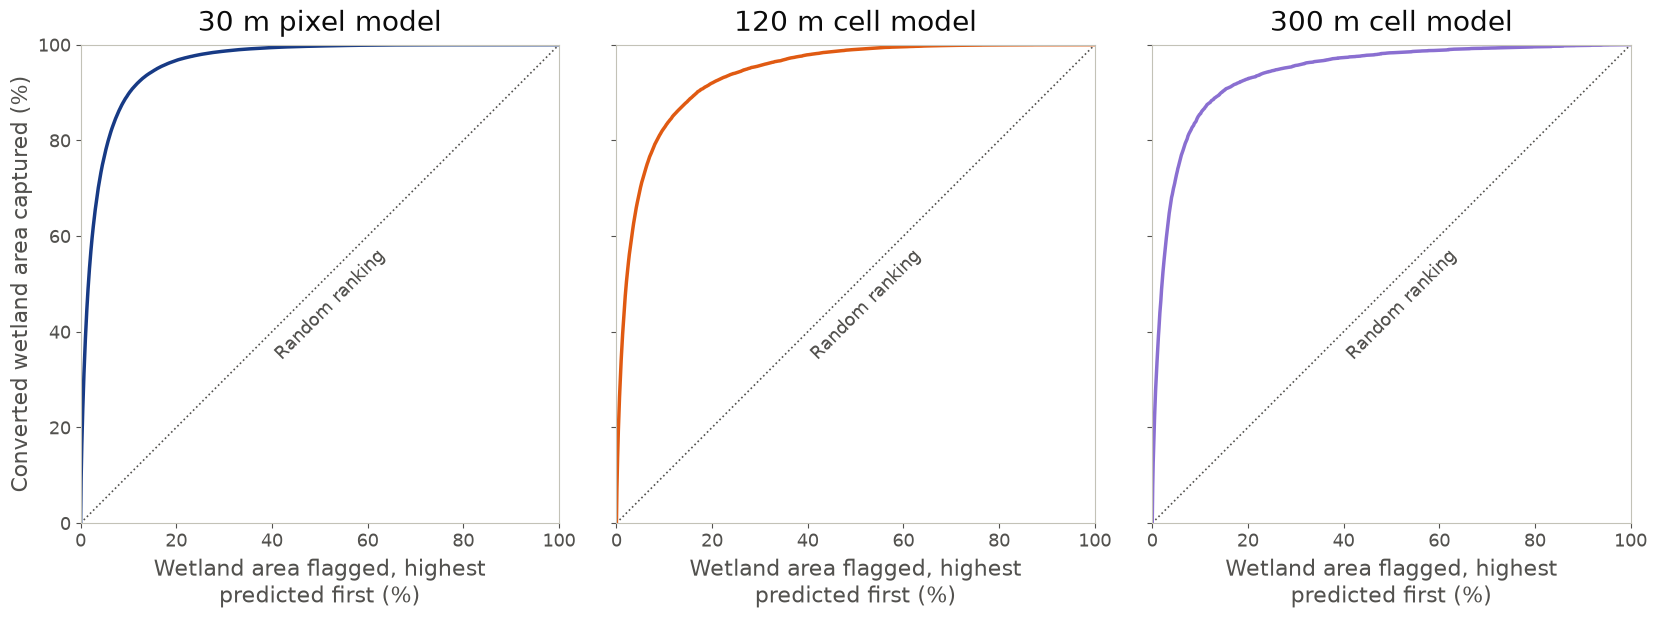

In [14]:
# same colors as the resolutions get elsewhere, checked under simulated deutan, protan and
# tritan color blindness (colorspacious, OKLab ΔE ×100, closest pair 21.5)
RES_COLOR = {"30 m pixels": "#173a85", "120 m cells": "#e05a12", "300 m cells": "#8a6fd1"}

fig, axes = plt.subplots(1, 3, figsize=(20, 7.4), sharey=True, gridspec_kw={"wspace": 0.12})
for ax, (name, y) in zip(axes, capture.items()):
    ax.plot([0, 100], [0, 100], color=MUTED, linewidth=1.2, linestyle=":")
    ax.plot(AREA_GRID * 100, y * 100, color=RES_COLOR[name], linewidth=2.5)

    # under the diagonal, where no curve ever goes
    ax.text(42, 34, "Random ranking", rotation=45, rotation_mode="anchor", fontsize=13, color=MUTED)

    ax.set_title(f"{name[:-1].capitalize()} model", fontsize=20, color=INK, pad=10)
    ax.set_xlabel("Wetland area flagged, highest\npredicted first (%)", fontsize=16, color=MUTED)
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 100)
    ax.set_aspect("equal")
    ax.tick_params(labelsize=13, colors=MUTED)
    for s in ax.spines.values():
        s.set_color("#c3c2b7")
axes[0].set_ylabel("Converted wetland area captured (%)", fontsize=16, color=MUTED)

out = ROOT / "results/figures/capture_curve_by_resolution.png"
fig.savefig(out, dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

In [16]:
from sklearn.isotonic import IsotonicRegression


def load_preds(path):
    """(pred, target, n_wetland) for one preds file. A pixel is a cell of one wetland pixel
    whose target is its 0 or 1 label, so the same sums work at every resolution."""
    with np.load(path) as z:
        if "probs" in z:
            p, t = z["probs"].astype(np.float64), z["labels"].astype(np.float64)
            return p, t, np.ones_like(t)
        return z["pred"].astype(np.float64), z["target"].astype(np.float64), z["n_wetland"].astype(np.float64)


# Focal loss scores aren't probabilities (they sum to about 14x the real conversions), so the
# raw pixel Brier score mostly measures that. The calibrated row fits isotonic regression per
# fold on that fold's training predictions, so no held out label touches it. Those are scores
# on rows the model trained on, which may run a bit more confident than on held out rows.
SKILL_RUNS = {**CAPTURE_RUNS, "30 m pixels, calibrated": CAPTURE_RUNS["30 m pixels"]}

rows = []
for name, run in SKILL_RUNS.items():
    for k in range(5):
        # the pixel run's train_preds only keeps every 10th training row (train_eval_stride),
        # which is plenty to pin down the training conversion rate and fit the calibration
        tr_p, tr_t, tr_w = load_preds(run / f"fold_{k}/train_preds.npz")
        p, t, w = load_preds(run / f"fold_{k}/val_preds.npz")
        if name.endswith("calibrated"):
            p = IsotonicRegression(y_min=0, y_max=1, out_of_bounds="clip").fit(tr_p, tr_t).predict(p)
        # The baseline only sees the training folds, same as the model. The pixel weighted
        # mean (the pixel conversion rate) is the constant that minimizes pixel weighted MSE,
        # and the plain cell average is the one for the unweighted version.
        rate_px = np.sum(tr_t * tr_w) / tr_w.sum()
        rate_cell = tr_t.mean()
        # strictest bar: a constant that already knows this fold's held out rate
        rate_val = np.sum(t * w) / w.sum()
        # store sums, not means, so the pooled row is just a column sum
        rows.append(dict(resolution=name, fold=k, cells=len(t), wetland_px=w.sum(),
                         converted_px=np.sum(t * w), predicted_px=np.sum(p * w),
                         sse_model=np.sum(w * (p - t) ** 2),
                         sse_train_mean=np.sum(w * (rate_px - t) ** 2),
                         sse_val_mean=np.sum(w * (rate_val - t) ** 2),
                         sse_model_cell=np.sum((p - t) ** 2),
                         sse_train_mean_cell=np.sum((rate_cell - t) ** 2)))
        del p, t, w, tr_p, tr_t, tr_w

per_fold = pd.DataFrame(rows)
pooled = per_fold.drop(columns="fold").groupby("resolution", sort=False).sum().assign(fold="pooled").reset_index()
s = pd.concat([per_fold.astype({"fold": str}), pooled], ignore_index=True).set_index(["resolution", "fold"])

skill = pd.DataFrame({
    "cells": s.cells,
    "positive_rate": s.converted_px / s.wetland_px,
    "pred_over_actual": s.predicted_px / s.converted_px,
    "mse_weighted": s.sse_model / s.wetland_px,
    "mse_baseline": s.sse_train_mean / s.wetland_px,
    "bss_weighted": 1 - s.sse_model / s.sse_train_mean,
    "bss_vs_val_mean": 1 - s.sse_model / s.sse_val_mean,
    "bss_unweighted": 1 - s.sse_model_cell / s.sse_train_mean_cell,
})
print("baseline: a constant at the training folds' conversion rate. Weighted columns count every wetland pixel "
      "once, unweighted count every cell once. positive_rate is the share of held out wetland pixels that converted. "
      "For 30 m pixels every unit is one pixel, so weighted and unweighted are the same Brier score.")
skill.style.format({"cells": "{:,}", "positive_rate": "{:.4%}", "pred_over_actual": "{:.2f}",
                    "mse_weighted": "{:.6f}", "mse_baseline": "{:.6f}",
                    **{c: "{:.3f}" for c in skill.columns if c.startswith("bss")}})

baseline: a constant at the training folds' conversion rate. Weighted columns count every wetland pixel once, unweighted count every cell once. positive_rate is the share of held out wetland pixels that converted. For 30 m pixels every unit is one pixel, so weighted and unweighted are the same Brier score.
